### Andriy Kardash - 50%
### Andrii Novitskyi - 50%

In [33]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix
)
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

train_data = pd.read_csv("processed_data/train_preprocessed.csv")
test_data = pd.read_csv("processed_data/test_preprocessed.csv")

X_train = train_data.drop(columns="failure")
y_train = train_data["failure"]

X_test = test_data.drop(columns="failure")
y_test = test_data["failure"]

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

X_train shape: (9849, 10)
X_test shape: (2462, 10)


In [21]:
print("Missing values in X_train:", X_train.isna().sum().sum())
print("Missing values in X_test:", X_test.isna().sum().sum())

print("\nTraining target distribution:")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts())
print(y_test.value_counts(normalize=True))

print("\nAll features numerical:", all(X_train.dtypes.apply(
    lambda dtype: pd.api.types.is_numeric_dtype(dtype)
)))

Missing values in X_train: 0
Missing values in X_test: 0

Training target distribution:
failure
0    8655
1    1194
Name: count, dtype: int64
failure
0    0.878769
1    0.121231
Name: proportion, dtype: float64

Test target distribution:
failure
0    2163
1     299
Name: count, dtype: int64
failure
0    0.878554
1    0.121446
Name: proportion, dtype: float64

All features numerical: True


### ID3 Implementation

In [22]:
def entropy(y):
    y = np.asarray(y)

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(
        probabilities * np.log2(probabilities)
    )
    

In [23]:

print("Training target entropy:", entropy(y_train))

Training target entropy: 0.532887820692801


In [24]:
def information_gain(y, left_mask):
    y = np.asarray(y)
    left_mask = np.asarray(left_mask)

    y_left = y[left_mask]
    y_right = y[~left_mask]

    if len(y_left) == 0 or len(y_right) == 0:
        return 0.0

    parent_entropy = entropy(y)

    children_entropy = (
        len(y_left) / len(y) * entropy(y_left)
        + len(y_right) / len(y) * entropy(y_right)
    )

    return parent_entropy - children_entropy

In [25]:
feature = X_train.columns[0]
threshold = X_train[feature].median()

left_mask = X_train[feature] <= threshold

gain = information_gain(y_train, left_mask)

print("Feature:", feature)
print("Threshold:", threshold)
print("Parent entropy:", entropy(y_train))
print("Left entropy:", entropy(y_train[left_mask]))
print("Right entropy:", entropy(y_train[~left_mask]))
print("Information gain:", gain)
print("Left observations:", left_mask.sum())
print("Right observations:", (~left_mask).sum())

Feature: skew__filter_dp
Threshold: 0.0045732354609044
Parent entropy: 0.532887820692801
Left entropy: 0.520356760387133
Right entropy: 0.5462372251518429
Information gain: 0.00013870861205733664
Left observations: 5133
Right observations: 4716


In [26]:
def find_best_split(
    X,
    y,
    min_samples_leaf=20,
    number_of_thresholds=50
):
    best_feature = None
    best_threshold = None
    best_gain = 0.0

    for feature in X.columns:
        values = X[feature]

        thresholds = np.unique(
            np.quantile(
                values,
                np.linspace(0.02, 0.98, number_of_thresholds)
            )
        )

        for threshold in thresholds:
            left_mask = values <= threshold

            left_size = left_mask.sum()
            right_size = len(values) - left_size

            if (
                left_size < min_samples_leaf
                or right_size < min_samples_leaf
            ):
                continue

            gain = information_gain(y, left_mask)

            if gain > best_gain:
                best_feature = feature
                best_threshold = threshold
                best_gain = gain

    return {
        "feature": best_feature,
        "threshold": best_threshold,
        "information_gain": best_gain
    }

### Looks for the best feature an threshol to use by comparing result pf information_gain()


In [27]:
best_root_split = find_best_split(
    X_train,
    y_train
)

best_root_split

{'feature': 'bin__filter_dp_missing',
 'threshold': np.float64(0.0),
 'information_gain': np.float64(0.034039045703320614)}

In [28]:
def build_id3_tree(X, y, depth=0, max_depth=2):
    prediction = int(y.mode().iloc[0])

    # Stop and create a leaf
    if (
        depth >= max_depth
        or y.nunique() == 1
        or len(y) < 40
    ):
        return {
            "is_leaf": True,
            "prediction": prediction,
            "samples": len(y)
        }

    split = find_best_split(
        X,
        y,
        min_samples_leaf=20
    )

    # Stop if no useful split exists
    if split["feature"] is None:
        return {
            "is_leaf": True,
            "prediction": prediction,
            "samples": len(y)
        }

    feature = split["feature"]
    threshold = split["threshold"]

    left_mask = X[feature] <= threshold

    return {
        "is_leaf": False,
        "feature": feature,
        "threshold": float(threshold),
        "information_gain": float(split["information_gain"]),
        "prediction": prediction,
        "samples": len(y),

        "left": build_id3_tree(
            X[left_mask],
            y[left_mask],
            depth + 1,
            max_depth
        ),

        "right": build_id3_tree(
            X[~left_mask],
            y[~left_mask],
            depth + 1,
            max_depth
        )
    }

In [29]:
id3_tree = build_id3_tree(
    X_train,
    y_train,
    max_depth=2
)

id3_tree

{'is_leaf': False,
 'feature': 'bin__filter_dp_missing',
 'threshold': 0.0,
 'information_gain': 0.034039045703320614,
 'prediction': 0,
 'samples': 9849,
 'left': {'is_leaf': False,
  'feature': 'bin__vibrationRms_missing',
  'threshold': 0.0,
  'information_gain': 0.0332607738658125,
  'prediction': 0,
  'samples': 9432,
  'left': {'is_leaf': True, 'prediction': 0, 'samples': 9069},
  'right': {'is_leaf': True, 'prediction': 1, 'samples': 363}},
 'right': {'is_leaf': False,
  'feature': 'cat__versionFirmware_v3.4.1',
  'threshold': 0.0,
  'information_gain': 0.04012201332534082,
  'prediction': 1,
  'samples': 417,
  'left': {'is_leaf': True, 'prediction': 0, 'samples': 221},
  'right': {'is_leaf': True, 'prediction': 1, 'samples': 196}}}

In [30]:
def predict_one(row, tree):
    if tree["is_leaf"]:
        return tree["prediction"]

    if row[tree["feature"]] <= tree["threshold"]:
        return predict_one(row, tree["left"])

    return predict_one(row, tree["right"])


def predict_id3(X, tree):
    return np.array([
        predict_one(row, tree)
        for _, row in X.iterrows()
    ])

In [31]:
y_train_pred_id3 = predict_id3(X_train, id3_tree)
y_test_pred_id3 = predict_id3(X_test, id3_tree)

print("First 20 predictions:")
print(y_test_pred_id3[:20])

First 20 predictions:
[0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [32]:
id3_results = pd.DataFrame({
    "dataset": ["Train", "Test"],

    "accuracy": [
        accuracy_score(y_train, y_train_pred_id3),
        accuracy_score(y_test, y_test_pred_id3)
    ],

    "precision": [
        precision_score(
            y_train,
            y_train_pred_id3,
            zero_division=0
        ),
        precision_score(
            y_test,
            y_test_pred_id3,
            zero_division=0
        )
    ],

    "recall": [
        recall_score(
            y_train,
            y_train_pred_id3,
            zero_division=0
        ),
        recall_score(
            y_test,
            y_test_pred_id3,
            zero_division=0
        )
    ]
})

display(id3_results)

,dataset,accuracy,precision,recall
0,Train,0.887400,0.576029,0.269682
1,Test,0.883834,0.546763,0.254181


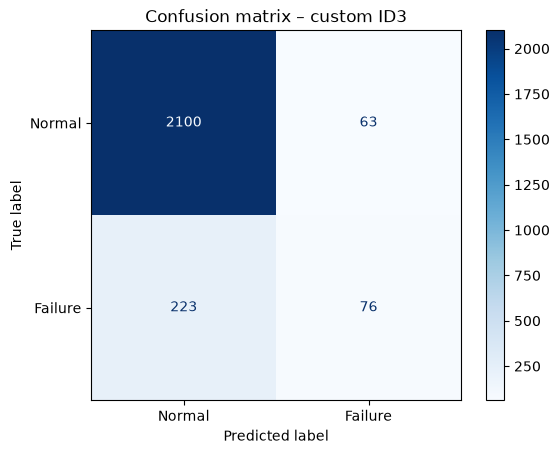

In [34]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_id3,
    display_labels=["Normal", "Failure"],
    cmap="Blues"
)

plt.title("Confusion matrix – custom ID3")
plt.show()

### The ID3 classifier correctly classified 2,176 of 2,462 test observations and made 286 incorrect predictions. Most errors were false negatives: the model missed 223 actual failures, while 63 normal observations were incorrectly classified as failures. Therefore, the model predicts normal operation well but has difficulty detecting failures.

,depth,train_accuracy,test_accuracy,train_precision,test_precision,train_recall,test_recall
0,1,0.882526,0.879366,0.544365,0.509804,0.190117,0.173913
1,2,0.887400,0.883834,0.576029,0.546763,0.269682,0.254181
2,3,0.891360,0.886677,0.663158,0.592593,0.211055,0.214047
3,4,0.893695,0.887896,0.684211,0.609524,0.228643,0.214047
4,5,0.895421,0.889115,0.696172,0.614035,0.243719,0.234114
5,6,0.899178,0.890333,0.725843,0.626087,0.270519,0.240803
6,7,0.899990,0.889521,0.744731,0.613445,0.266332,0.244147
7,8,0.901716,0.885459,0.716475,0.555556,0.313233,0.284281


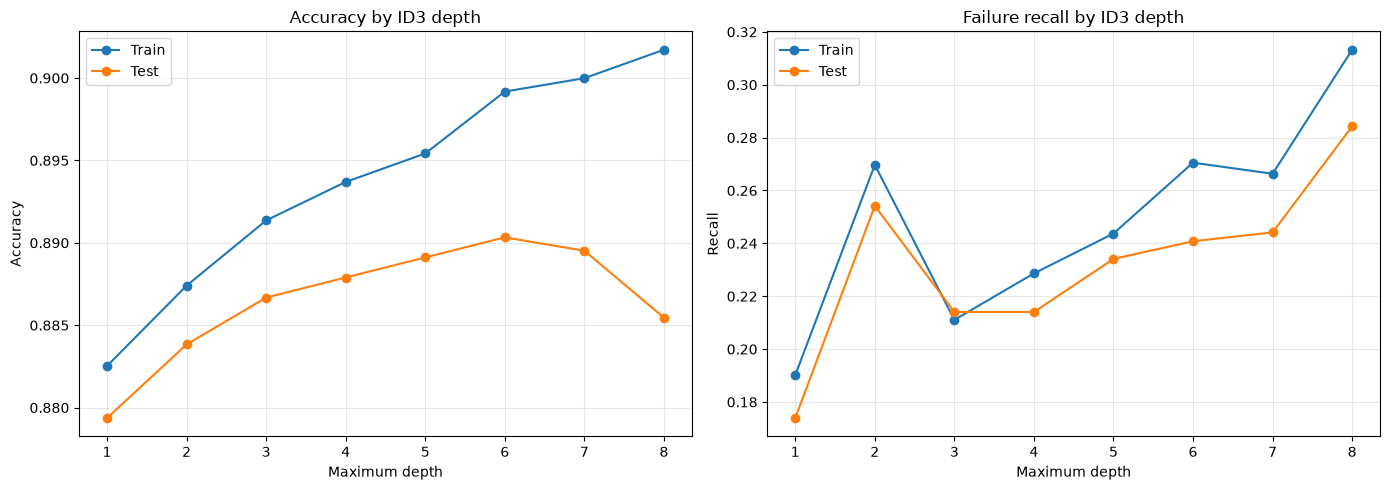

In [36]:
depth_results = []
depth_trees = {}

for depth in range(1, 9):
    tree = build_id3_tree(
        X_train,
        y_train,
        max_depth=depth
    )

    train_predictions = predict_id3(X_train, tree)
    test_predictions = predict_id3(X_test, tree)

    depth_results.append({
        "depth": depth,

        "train_accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "test_accuracy": accuracy_score(
            y_test, test_predictions
        ),

        "train_precision": precision_score(
            y_train, train_predictions, zero_division=0
        ),
        "test_precision": precision_score(
            y_test, test_predictions, zero_division=0
        ),

        "train_recall": recall_score(
            y_train, train_predictions, zero_division=0
        ),
        "test_recall": recall_score(
            y_test, test_predictions, zero_division=0
        )
    })

    depth_trees[depth] = tree

depth_results = pd.DataFrame(depth_results)

display(depth_results)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    depth_results["depth"],
    depth_results["train_accuracy"],
    marker="o",
    label="Train"
)
axes[0].plot(
    depth_results["depth"],
    depth_results["test_accuracy"],
    marker="o",
    label="Test"
)
axes[0].set_title("Accuracy by ID3 depth")
axes[0].set_xlabel("Maximum depth")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    depth_results["depth"],
    depth_results["train_recall"],
    marker="o",
    label="Train"
)
axes[1].plot(
    depth_results["depth"],
    depth_results["test_recall"],
    marker="o",
    label="Test"
)
axes[1].set_title("Failure recall by ID3 depth")
axes[1].set_xlabel("Maximum depth")
axes[1].set_ylabel("Recall")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Increasing the maximum depth initially improved ID3 performance. The depth-6 tree achieved the highest test accuracy (0.890) and test precision(0.626), while its training and test results remained reasonably close. At depth 8, training performance continued to improve, but test accuracy and precision decreased and the train-test gap increased, indicating the beginning of overfitting.

In [37]:
best_id3_depth = 6
best_id3_tree = depth_trees[best_id3_depth]

y_train_pred_best_id3 = predict_id3(
    X_train,
    best_id3_tree
)

y_test_pred_best_id3 = predict_id3(
    X_test,
    best_id3_tree
)

best_id3_results = pd.DataFrame({
    "dataset": ["Train", "Test"],
    "accuracy": [
        accuracy_score(y_train, y_train_pred_best_id3),
        accuracy_score(y_test, y_test_pred_best_id3)
    ],
    "precision": [
        precision_score(y_train, y_train_pred_best_id3),
        precision_score(y_test, y_test_pred_best_id3)
    ],
    "recall": [
        recall_score(y_train, y_train_pred_best_id3),
        recall_score(y_test, y_test_pred_best_id3)
    ]
})

display(best_id3_results)

,dataset,accuracy,precision,recall
0,Train,0.899178,0.725843,0.270519
1,Test,0.890333,0.626087,0.240803


### depth 6 was chose as the one with the best result before overfitting